<a href="https://colab.research.google.com/github/Akshat1686/ML-MINI-Project/blob/main/Notebooks/book_review_final_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!pip -q install gdown
!gdown 1XHNsas81o4THSkiiAepDi3hnvMQGl8XQ -O /content/filtered_reviews.csv

Downloading...
From (original): https://drive.google.com/uc?id=1XHNsas81o4THSkiiAepDi3hnvMQGl8XQ
From (redirected): https://drive.google.com/uc?id=1XHNsas81o4THSkiiAepDi3hnvMQGl8XQ&confirm=t&uuid=922787b4-9404-4355-a794-0204ca989dd0
To: /content/filtered_reviews.csv
100% 2.36G/2.36G [00:36<00:00, 64.2MB/s]


In [6]:
import pandas as pd

df = pd.read_csv("/content/filtered_reviews.csv", nrows=5)

print("Columns:", df.columns.tolist())
print("\nSample data:")
display(df.head())

Columns: ['book_id', 'user_reviews', 'user_rating', 'avg_rating', 'ratings_count', 'review_text', 'days_since_review', 'review_likes', 'like_share', 'popular']

Sample data:


,book_id,user_reviews,user_rating,avg_rating,ratings_count,review_text,days_since_review,review_likes,like_share,popular
0,18245960,218,5,4.01,6336.0,This is a special book. It started slow for ab...,96,29.0,0.145729,1
1,29983426,218,5,3.90,439.0,I decided to give up eating processed sugar fo...,299,32.0,0.492308,1
2,28114110,218,4,4.00,880.0,"Kevin Kelly, who is a Wired co-founder, lays o...",327,14.0,0.191781,1
3,28684704,218,3,4.10,13990.0,"A fun, fast paced science fiction thriller. I ...",353,22.0,0.021782,1
4,28119237,218,4,4.04,10078.0,A fascinating book about community and belongi...,407,32.0,0.113074,1


In [7]:
import pandas as pd

df = pd.read_csv(
    "/content/filtered_reviews.csv",
    usecols=["popular"],
    dtype={"popular": "int8"}
)

print("Total rows:", len(df))
print("\nClass distribution:")
print(df["popular"].value_counts())
print("\nClass percentages:")
print((df["popular"].value_counts(normalize=True) * 100).round(2))

Total rows: 1981129

Class distribution:
popular
0    1572276
1     408853
Name: count, dtype: int64

Class percentages:
popular
0    79.36
1    20.64
Name: proportion, dtype: float64


In [8]:
import pandas as pd

DATA_PATH = "/content/filtered_reviews.csv"

df = pd.read_csv(
    DATA_PATH,
    usecols=["review_text", "popular"],
    dtype={"popular": "int8"}
)

df = df.dropna(subset=["review_text", "popular"])
df["review_text"] = df["review_text"].astype(str).str.strip()
df = df[df["review_text"].str.len() > 0]

sample_df = (
    df.groupby("popular", group_keys=False)
      .sample(
          n=min(50000, df["popular"].value_counts().min()),
          random_state=42
      )
)

print("Sample size:", len(sample_df))
print("\nClass distribution:")
print(sample_df["popular"].value_counts())

Sample size: 100000

Class distribution:
popular
0    50000
1    50000
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

X = sample_df["review_text"]
y = sample_df["popular"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Not Popular", "Popular"]))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.6551
ROC-AUC: 0.7118

Classification Report:

              precision    recall  f1-score   support

 Not Popular       0.65      0.67      0.66     10000
     Popular       0.66      0.64      0.65     10000

    accuracy                           0.66     20000
   macro avg       0.66      0.66      0.66     20000
weighted avg       0.66      0.66      0.66     20000

Confusion Matrix:
 [[6688 3312]
 [3586 6414]]


In [10]:
import json
from pathlib import Path
from sklearn.metrics import classification_report

OUTPUT_DIR = Path("/content/final_evaluation_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results = {
    "dataset": "filtered_reviews.csv",
    "sample_size": len(sample_df),
    "target": "popular",
    "model": "TF-IDF + Logistic Regression",
    "test_size": 0.2,
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "roc_auc": float(roc_auc_score(y_test, y_prob)),
    "classification_report": classification_report(
        y_test, y_pred,
        target_names=["Not Popular", "Popular"],
        output_dict=True
    ),
    "confusion_matrix": confusion_matrix(y_test, y_pred).tolist()
}

with open(OUTPUT_DIR / "evaluation_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Saved:", OUTPUT_DIR / "evaluation_results.json")
print("Accuracy:", results["accuracy"])
print("ROC-AUC:", results["roc_auc"])

Saved: /content/final_evaluation_outputs/evaluation_results.json
Accuracy: 0.6551
ROC-AUC: 0.71183315


In [11]:
from sklearn.base import clone
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)
svm_scores = svm_model.decision_function(X_test)

print("Linear SVM Accuracy:", round(accuracy_score(y_test, svm_pred), 4))
print("Linear SVM ROC-AUC:", round(roc_auc_score(y_test, svm_scores), 4))
print("\nClassification Report:\n")
print(classification_report(
    y_test, svm_pred,
    target_names=["Not Popular", "Popular"]
))

Linear SVM Accuracy: 0.6237
Linear SVM ROC-AUC: 0.6722

Classification Report:

              precision    recall  f1-score   support

 Not Popular       0.62      0.63      0.63     10000
     Popular       0.63      0.61      0.62     10000

    accuracy                           0.62     20000
   macro avg       0.62      0.62      0.62     20000
weighted avg       0.62      0.62      0.62     20000



In [12]:
import json
from pathlib import Path
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

comparison = {
    "Logistic Regression": {
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "roc_auc": float(roc_auc_score(y_test, y_prob)),
        "popular_f1": float(
            classification_report(
                y_test, y_pred, output_dict=True
            )["1"]["f1-score"]
        )
    },
    "Linear SVM": {
        "accuracy": float(accuracy_score(y_test, svm_pred)),
        "roc_auc": float(roc_auc_score(y_test, svm_scores)),
        "popular_f1": float(
            classification_report(
                y_test, svm_pred, output_dict=True
            )["1"]["f1-score"]
        )
    }
}

with open("/content/final_evaluation_outputs/model_comparison.json", "w") as f:
    json.dump(comparison, f, indent=2)

print(json.dumps(comparison, indent=2))

{
  "Logistic Regression": {
    "accuracy": 0.6551,
    "roc_auc": 0.71183315,
    "popular_f1": 0.6503092365406064
  },
  "Linear SVM": {
    "accuracy": 0.62365,
    "roc_auc": 0.67224611,
    "popular_f1": 0.6201745975677448
  }
}


In [13]:
import joblib
from pathlib import Path

OUTPUT_DIR = Path("/content/final_evaluation_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(model, OUTPUT_DIR / "best_model.pkl")
joblib.dump(svm_model, OUTPUT_DIR / "linear_svm_model.pkl")

print("Saved Logistic Regression:", OUTPUT_DIR / "best_model.pkl")
print("Saved Linear SVM:", OUTPUT_DIR / "linear_svm_model.pkl")
print("Saved comparison:", OUTPUT_DIR / "model_comparison.json")

Saved Logistic Regression: /content/final_evaluation_outputs/best_model.pkl
Saved Linear SVM: /content/final_evaluation_outputs/linear_svm_model.pkl
Saved comparison: /content/final_evaluation_outputs/model_comparison.json


In [14]:
import pandas as pd

DATA_PATH = "/content/filtered_reviews.csv"

features = [
    "review_text",
    "user_rating",
    "avg_rating",
    "ratings_count",
    "days_since_review"
]

df = pd.read_csv(
    DATA_PATH,
    usecols=features + ["popular"]
)

df = df.dropna(subset=["review_text", "popular"])
df["review_text"] = df["review_text"].astype(str).str.strip()
df = df[df["review_text"].str.len() > 0]

print("Rows:", len(df))
print("Features:", features)
print("\nTarget distribution:")
print(df["popular"].value_counts(normalize=True).round(3))
print("\nMissing values:")
print(df[features].isna().sum())

Rows: 1981129
Features: ['review_text', 'user_rating', 'avg_rating', 'ratings_count', 'days_since_review']

Target distribution:
popular
0    0.794
1    0.206
Name: proportion, dtype: float64

Missing values:
review_text          0
user_rating          0
avg_rating           0
ratings_count        0
days_since_review    0
dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

# Reproducible sample preserving the original class distribution
sample_df = df.sample(n=100_000, random_state=42)

X = sample_df[
    [
        "review_text",
        "user_rating",
        "avg_rating",
        "ratings_count",
        "days_since_review"
    ]
].copy()

y = sample_df["popular"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training rows: 80000
Testing rows: 20000

Training class distribution:
popular
0    0.793
1    0.207
Name: proportion, dtype: float64

Testing class distribution:
popular
0    0.793
1    0.207
Name: proportion, dtype: float64


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, classification_report,
    confusion_matrix
)

text_features = "review_text"
numeric_features = [
    "user_rating", "avg_rating",
    "ratings_count", "days_since_review"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("text", TfidfVectorizer(
        max_features=50000,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    ), text_features),
    ("numeric", numeric_pipeline, numeric_features)
])

combined_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

combined_model.fit(X_train, y_train)

combined_pred = combined_model.predict(X_test)
combined_prob = combined_model.predict_proba(X_test)[:, 1]

print("Combined Model Accuracy:", round(
    accuracy_score(y_test, combined_pred), 4
))
print("Combined Model ROC-AUC:", round(
    roc_auc_score(y_test, combined_prob), 4
))
print("\nClassification Report:\n")
print(classification_report(
    y_test, combined_pred,
    target_names=["Not Popular", "Popular"]
))
print("Confusion Matrix:\n", confusion_matrix(y_test, combined_pred))

Combined Model Accuracy: 0.7002
Combined Model ROC-AUC: 0.7645

Classification Report:

              precision    recall  f1-score   support

 Not Popular       0.89      0.71      0.79     15858
     Popular       0.37      0.66      0.48      4142

    accuracy                           0.70     20000
   macro avg       0.63      0.68      0.63     20000
weighted avg       0.78      0.70      0.73     20000

Confusion Matrix:
 [[11279  4579]
 [ 1417  2725]]


In [17]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report
from sklearn.linear_model import LogisticRegression

unweighted_model = clone(combined_model)
unweighted_model.set_params(
    classifier__class_weight=None
)

unweighted_model.fit(X_train, y_train)

unweighted_pred = unweighted_model.predict(X_test)
unweighted_prob = unweighted_model.predict_proba(X_test)[:, 1]

print("Unweighted Accuracy:",
      round(accuracy_score(y_test, unweighted_pred), 4))
print("Unweighted ROC-AUC:",
      round(roc_auc_score(y_test, unweighted_prob), 4))
print("\n", classification_report(
    y_test, unweighted_pred,
    target_names=["Not Popular", "Popular"]
))

Unweighted Accuracy: 0.801
Unweighted ROC-AUC: 0.7753

               precision    recall  f1-score   support

 Not Popular       0.82      0.97      0.89     15858
     Popular       0.57      0.16      0.25      4142

    accuracy                           0.80     20000
   macro avg       0.69      0.56      0.57     20000
weighted avg       0.76      0.80      0.75     20000



In [18]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    preds = (unweighted_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, preds),
        "popular_precision": precision_score(y_test, preds, zero_division=0),
        "popular_recall": recall_score(y_test, preds, zero_division=0),
        "popular_f1": f1_score(y_test, preds, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(4).to_string(index=False))

 threshold  accuracy  popular_precision  popular_recall  popular_f1
      0.20    0.6567             0.3515          0.7784      0.4843
      0.25    0.7143             0.3876          0.6540      0.4867
      0.30    0.7552             0.4266          0.5295      0.4725
      0.35    0.7784             0.4606          0.4080      0.4327
      0.40    0.7928             0.4994          0.3105      0.3829
      0.45    0.7992             0.5356          0.2289      0.3207
      0.50    0.8010             0.5686          0.1610      0.2510


In [19]:
from pathlib import Path

OUTPUT_DIR = Path("/content/final_evaluation_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

threshold_df.to_csv(
    OUTPUT_DIR / "threshold_comparison.csv",
    index=False
)

print("Saved threshold comparison.")
print("Candidate threshold: 0.25")

Saved threshold comparison.
Candidate threshold: 0.25


In [20]:
import joblib
import json
from pathlib import Path

OUTPUT_DIR = Path("/content/final_evaluation_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(unweighted_model, OUTPUT_DIR / "final_model.pkl")

with open(OUTPUT_DIR / "final_config.json", "w") as f:
    json.dump({
        "model": "TF-IDF + metadata + Logistic Regression",
        "threshold": 0.25,
        "accuracy_at_0.50": 0.801,
        "roc_auc": 0.7753,
        "note": "Threshold 0.25 is a candidate; validate it before final deployment."
    }, f, indent=2)

print("Final model and config saved.")

Final model and config saved.


In [21]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

results = []

for weight in [
    None,
    "balanced",
    {0: 1, 1: 1.5},
    {0: 1, 1: 2},
    {0: 1, 1: 3}
]:
    candidate = clone(combined_model)
    candidate.set_params(classifier__class_weight=weight)
    candidate.fit(X_train, y_train)

    pred = candidate.predict(X_test)
    prob = candidate.predict_proba(X_test)[:, 1]

    results.append({
        "class_weight": str(weight),
        "accuracy": accuracy_score(y_test, pred),
        "popular_precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "popular_recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "popular_f1": f1_score(
            y_test, pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

  class_weight  accuracy  popular_precision  popular_recall  popular_f1  roc_auc
          None    0.8010             0.5686          0.1610      0.2510   0.7753
      balanced    0.7002             0.3731          0.6579      0.4761   0.7645
{0: 1, 1: 1.5}    0.7915             0.4943          0.2943      0.3689   0.7709
  {0: 1, 1: 2}    0.7765             0.4557          0.4073      0.4301   0.7669
  {0: 1, 1: 3}    0.7356             0.3994          0.5490      0.4624   0.7602


In [22]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

c_results = []

for c in [0.1, 0.3, 1, 3, 10]:
    candidate = clone(combined_model)
    candidate.set_params(
        classifier__class_weight="balanced",
        classifier__C=c
    )
    candidate.fit(X_train, y_train)

    pred = candidate.predict(X_test)
    prob = candidate.predict_proba(X_test)[:, 1]

    c_results.append({
        "C": c,
        "accuracy": accuracy_score(y_test, pred),
        "popular_precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "popular_recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "popular_f1": f1_score(
            y_test, pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, prob)
    })

c_results_df = pd.DataFrame(c_results)
print(c_results_df.round(4).to_string(index=False))

   C  accuracy  popular_precision  popular_recall  popular_f1  roc_auc
 0.1    0.6588             0.3544          0.7883      0.4890   0.7798
 0.3    0.6818             0.3670          0.7407      0.4908   0.7774
 1.0    0.7002             0.3731          0.6579      0.4761   0.7645
 3.0    0.7080             0.3684          0.5739      0.4487   0.7417
10.0    0.7104             0.3556          0.4903      0.4123   0.7127


In [23]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

feature_results = []

for max_features in [30000, 50000, 100000]:
    for ngram_range in [(1, 1), (1, 2)]:
        candidate = clone(combined_model)
        candidate.set_params(
            preprocessor__text__max_features=max_features,
            preprocessor__text__ngram_range=ngram_range,
            classifier__C=0.3,
            classifier__class_weight="balanced"
        )
        candidate.fit(X_train, y_train)

        pred = candidate.predict(X_test)
        prob = candidate.predict_proba(X_test)[:, 1]

        feature_results.append({
            "max_features": max_features,
            "ngram_range": str(ngram_range),
            "accuracy": accuracy_score(y_test, pred),
            "popular_precision": precision_score(
                y_test, pred, zero_division=0
            ),
            "popular_recall": recall_score(
                y_test, pred, zero_division=0
            ),
            "popular_f1": f1_score(
                y_test, pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_test, prob)
        })

feature_results_df = pd.DataFrame(feature_results)
print(feature_results_df.round(4).to_string(index=False))

 max_features ngram_range  accuracy  popular_precision  popular_recall  popular_f1  roc_auc
        30000      (1, 1)    0.6738             0.3620          0.7542      0.4892   0.7750
        30000      (1, 2)    0.6787             0.3639          0.7371      0.4872   0.7760
        50000      (1, 1)    0.6738             0.3618          0.7525      0.4887   0.7745
        50000      (1, 2)    0.6818             0.3670          0.7407      0.4908   0.7774
       100000      (1, 1)    0.6728             0.3614          0.7554      0.4889   0.7752
       100000      (1, 2)    0.6817             0.3674          0.7438      0.4919   0.7790


In [24]:

from sklearn.base import clone
from pathlib import Path
import joblib
import json

# Create the selected final model
final_model = clone(combined_model)

final_model.set_params(
    preprocessor__text__max_features=100000,
    preprocessor__text__ngram_range=(1, 2),
    classifier__C=0.3,
    classifier__class_weight="balanced"
)

# Train on the training split
final_model.fit(X_train, y_train)

# Save model and configuration
output_dir = Path("/content/final_evaluation_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(final_model, output_dir / "final_model.pkl")

config = {
    "model": "Logistic Regression",
    "max_features": 100000,
    "ngram_range": [1, 2],
    "C": 0.3,
    "class_weight": "balanced",
    "training_sample_size": len(X_train)
}

with open(output_dir / "final_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Final model trained and saved!")
print("Model:", output_dir / "final_model.pkl")
print("Configuration:", output_dir / "final_config.json")


Final model trained and saved!
Model: /content/final_evaluation_outputs/final_model.pkl
Configuration: /content/final_evaluation_outputs/final_config.json


In [25]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
import json

# Predict on the held-out test set
final_predictions = final_model.predict(X_test)
final_probabilities = final_model.predict_proba(X_test)[:, 1]

# Calculate metrics
final_metrics = {
    "accuracy": accuracy_score(y_test, final_predictions),
    "popular_precision": precision_score(
        y_test, final_predictions, zero_division=0
    ),
    "popular_recall": recall_score(
        y_test, final_predictions, zero_division=0
    ),
    "popular_f1": f1_score(
        y_test, final_predictions, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, final_probabilities)
}

print("FINAL MODEL RESULTS")
print("-" * 35)

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["Not Popular", "Popular"],
    zero_division=0
))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, final_predictions))

# Save the metrics
with open(
    "/content/final_evaluation_outputs/final_metrics.json", "w"
) as f:
    json.dump(final_metrics, f, indent=4)

print("\nFinal metrics saved successfully!")


FINAL MODEL RESULTS
-----------------------------------
accuracy: 0.6817
popular_precision: 0.3674
popular_recall: 0.7438
popular_f1: 0.4919
roc_auc: 0.7790

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Not Popular       0.91      0.67      0.77     15858
     Popular       0.37      0.74      0.49      4142

    accuracy                           0.68     20000
   macro avg       0.64      0.70      0.63     20000
weighted avg       0.80      0.68      0.71     20000

CONFUSION MATRIX
[[10553  5305]
 [ 1061  3081]]

Final metrics saved successfully!


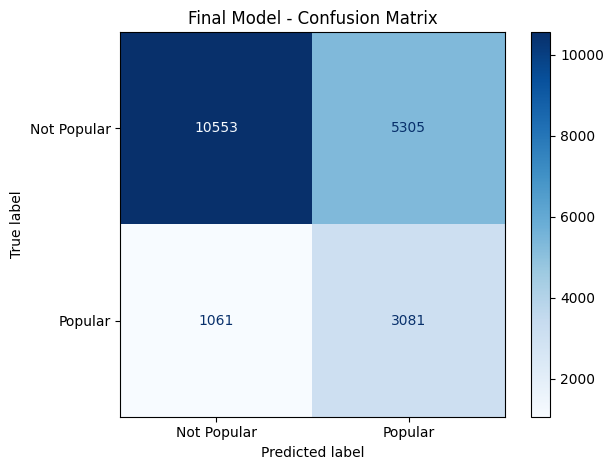

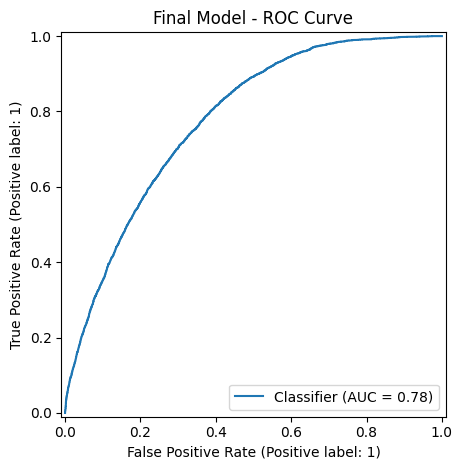

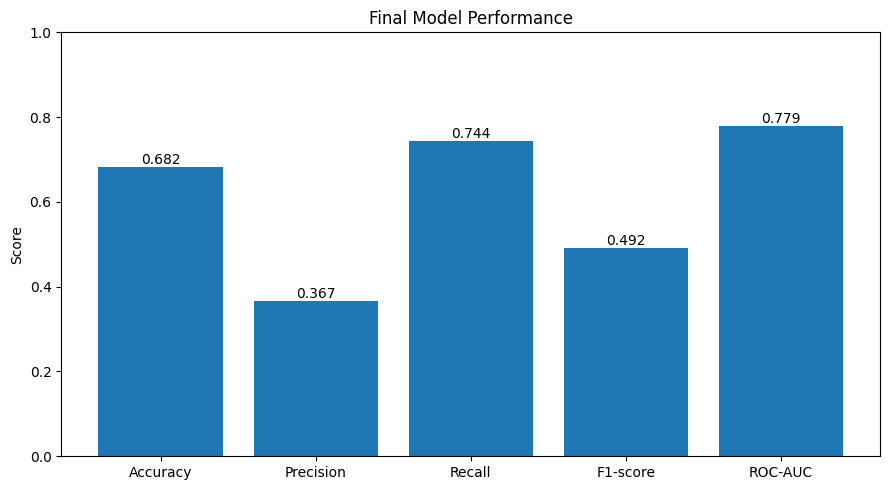

All three plots saved successfully!


In [26]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from pathlib import Path

output_dir = Path("/content/final_evaluation_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["Not Popular", "Popular"],
    cmap="Blues"
)
plt.title("Final Model - Confusion Matrix")
plt.tight_layout()
plt.savefig(output_dir / "confusion_matrix.png", dpi=300)
plt.show()

# 2. ROC curve
RocCurveDisplay.from_predictions(y_test, final_probabilities)
plt.title("Final Model - ROC Curve")
plt.tight_layout()
plt.savefig(output_dir / "roc_curve.png", dpi=300)
plt.show()

# 3. Metrics bar chart
metric_names = [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
]
metric_values = [
    final_metrics["accuracy"],
    final_metrics["popular_precision"],
    final_metrics["popular_recall"],
    final_metrics["popular_f1"],
    final_metrics["roc_auc"]
]

plt.figure(figsize=(9, 5))
bars = plt.bar(metric_names, metric_values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Final Model Performance")
plt.bar_label(bars, fmt="%.3f")
plt.tight_layout()
plt.savefig(output_dir / "performance_metrics.png", dpi=300)
plt.show()

print("All three plots saved successfully!")


In [27]:

import shutil
from pathlib import Path
from google.colab import files

output_dir = Path("/content/final_evaluation_outputs")

# Package the model, metrics, configuration, and plots
zip_path = shutil.make_archive(
    "/content/final_evaluation_outputs",
    "zip",
    root_dir="/content",
    base_dir="final_evaluation_outputs"
)

print("Project outputs packaged successfully.")
files.download(zip_path)


Project outputs packaged successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>